# 01 — Data Exploration

**Project 2.2 — Cross-Modal Retrieval: Mobile App Screens and Text Summaries**

Tess Santhosh (a2910201) · COMP 1030 Multimodal Data Analytics, Adelaide University


Quick look at RICO-Screen2Words before building anything: data quality, size, and whether screens
need to be grouped by app when splitting, to avoid leakage into train/val/test. No
modelling here, just the checks notebook `02_preprocessing_features.ipynb` depends on.

Outputs:
- `results/figures/fig1_sample_screens.png`
- `results/figures/fig2_caption_length_hist.png`
- `results/figures/fig3_screens_per_app.png`
- `results/figures/fig4_near_duplicate_pairs.png`
- `results/tables/data_summary.csv`

## Setup

Run this cell first — it clones the repo (so `src/utils.py` is importable), installs dependencies, and checks the GPU.



In [ ]:
#Repo setup
import os
import sys
import subprocess

REPO_URL = "https://github.com/tesssanthosh/cross-modal-retrieval-2.2.git"
REPO_DIR = "/content/cross-modal-retrieval-2.2"

if not os.path.isdir(REPO_DIR):
    subprocess.run(["git", "clone", REPO_URL, REPO_DIR], check=True)
else:
    subprocess.run(["git", "-C", REPO_DIR, "pull"], check=True)

os.chdir(REPO_DIR)
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

print("Working directory:", os.getcwd())


Working directory: /content/cross-modal-retrieval-2.2


In [ ]:
#Installing dependencies

!pip install -q -r requirements.txt
!pip install -q datasets


In [ ]:
#Imports, defining seed and device
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from src.utils import recall_at_k, retrieval_report, info_nce, count_parameters

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected change runtime type to T4 GPU, then re-run this cell.")


Device: cuda
GPU: Tesla T4


In [ ]:
#sanity check: a perfect 4x4 score matrix should give Recall@1 = 1.0.
toy_scores = torch.eye(4) * 10
print(retrieval_report(toy_scores, ks=(1,)))
assert retrieval_report(toy_scores, ks=(1,))["R@1 image->text"] == 1.0
print("src/utils.py sanity check passed.")


{'R@1 image->text': 1.0, 'R@1 text->image': 1.0, 'MRR image->text': 1.0, 'MRR text->image': 1.0, 'median_rank image->text': 1.0, 'median_rank text->image': 1.0, 'AUC': np.float64(1.0)}
src/utils.py sanity check passed.


## Load the dataset

RICO-Screen2Words ([dataset card](https://huggingface.co/datasets/rootsautomation/RICO-Screen2Words))
loads via the `datasets` library and no manual download.


In [ ]:
from datasets import load_dataset

ds = load_dataset("rootsautomation/RICO-Screen2Words")
print(ds)


README.md:   0%|          | 0.00/6.13k [00:00<?, ?B/s]

data/train-00000-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  216MB            

data/train-00000-of-00008.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  219MB            

data/train-00001-of-00008.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  225MB            

... (19 outputs left out)

Generating train split:   0%|          | 0/15743 [00:00<?, ? examples/s]

Generating val split:   0%|          | 0/2364 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/4310 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['screenId', 'captions', 'file_name', 'app_package_name', 'play_store_name', 'category', 'average_rating', 'number_of_ratings', 'number_of_downloads', 'file_name_icon', 'file_name_semantic', 'semantic_annotations', 'view_hierarchy', 'image', 'image_icon', 'image_semantic'],
        num_rows: 15743
    })
    val: Dataset({
        features: ['screenId', 'captions', 'file_name', 'app_package_name', 'play_store_name', 'category', 'average_rating', 'number_of_ratings', 'number_of_downloads', 'file_name_icon', 'file_name_semantic', 'semantic_annotations', 'view_hierarchy', 'image', 'image_icon', 'image_semantic'],
        num_rows: 2364
    })
    test: Dataset({
        features: ['screenId', 'captions', 'file_name', 'app_package_name', 'play_store_name', 'category', 'average_rating', 'number_of_ratings', 'number_of_downloads', 'file_name_icon', 'file_name_semantic', 'semantic_annotations', 'view_hierarchy', 'image', 'image_icon', 'imag

## Inspect the schema

We print the actual `Features` and one example, then detect the caption/image/id columns from
what's really there, instead of hardcoding guessed names.


In [ ]:
SPLIT = "train" if "train" in ds else list(ds.keys())[0]
split = ds[SPLIT]

print("Splits:", list(ds.keys()))
print()
print("Features:")
print(split.features)
print()
print("First example (keys only, values truncated):")
example = split[0]
for k, v in example.items():
    v_repr = repr(v)
    print(f"  {k}: {v_repr[:150]}{'...' if len(v_repr) > 150 else ''}")


Splits: ['train', 'val', 'test']

Features:
{'screenId': Value('int64'), 'captions': List(Value('string')), 'file_name': Value('string'), 'app_package_name': Value('string'), 'play_store_name': Value('string'), 'category': Value('string'), 'average_rating': Value('float64'), 'number_of_ratings': Value('string'), 'number_of_downloads': Value('string'), 'file_name_icon': Value('string'), 'file_name_semantic': Value('string'), 'semantic_annotations': Value('string'), 'view_hierarchy': Value('string'), 'image': Image(mode=None, decode=True), 'image_icon': Image(mode=None, decode=True), 'image_semantic': Image(mode=None, decode=True)}

First example (keys only, values truncated):
  screenId: 2
  captions: ['notification displaying a calendar with done option', 'pop up displaying a calendar', 'pop up displaying calendar to select date', 'pop up window of...
  file_name: 'rico/2.jpg'
  app_package_name: 'yong.app.videoeditor'
  play_store_name: 'Video Maker Pro Free'
  category: 'Video Player

In [ ]:
#Auto-detecting the columns we need
def first_present(candidates, columns):
    for c in candidates:
        if c in columns:
            return c
    return None

columns = split.column_names

IMAGE_COL = first_present(["image", "screenshot", "screen"], columns)
CAPTION_COL = first_present(["captions", "summaries", "caption", "summary"], columns)
ID_COL = first_present(["screenId", "screen_id", "id"], columns)
APP_COL = first_present(["app_package_name", "app_package", "package_name", "app"], columns)

print("IMAGE_COL   =", IMAGE_COL)
print("CAPTION_COL =", CAPTION_COL)
print("ID_COL      =", ID_COL)
print("APP_COL     =", APP_COL, "(None means app-level grouping needs another approach)")

assert IMAGE_COL is not None, "Could not find an image column, inspect `columns` above and set IMAGE_COL manually."
assert CAPTION_COL is not None, "Could not find a caption column, inspect `columns` above and set CAPTION_COL manually."


IMAGE_COL   = image
CAPTION_COL = captions
ID_COL      = screenId
APP_COL     = app_package_name (None means app-level grouping needs another approach)


## Dataset size and splits

In [ ]:
rows = []
for name, d in ds.items():
    n_rows = len(d)
    # handling both the captions stored as one list per screen or one row per caption
    sample_caption_val = d[0][CAPTION_COL]
    captions_are_listlike = isinstance(sample_caption_val, (list, tuple))
    n_captions = sum(len(r[CAPTION_COL]) for r in d) if captions_are_listlike else n_rows
    rows.append({"split": name, "rows": n_rows, "captions_are_list_per_row": captions_are_listlike,
                 "total_captions": n_captions})

split_summary = pd.DataFrame(rows)
split_summary


,split,rows,captions_are_list_per_row,total_captions
0,train,15743,True,78715
1,val,2364,True,11820
2,test,4310,True,21550


## Quality checks

Checks run on a random sample rather than all ~22k screens for exploration.


In [ ]:
N_SAMPLE = 500
rng = random.Random(SEED)
sample_idx = rng.sample(range(len(split)), min(N_SAMPLE, len(split)))

n_bad_images = 0
n_empty_captions = 0
caption_lengths = []

for i in sample_idx:
    row = split[i]
    try:
        img = row[IMAGE_COL]
        _ = img.size  # forces a decode and raises if corrupt
    except Exception as e:
        n_bad_images += 1

    cap_val = row[CAPTION_COL]
    caps = cap_val if isinstance(cap_val, (list, tuple)) else [cap_val]
    for c in caps:
        if c is None or len(c.strip()) == 0:
            n_empty_captions += 1
        else:
            caption_lengths.append(len(c.split()))

print(f"Sampled {len(sample_idx)} screens:")
print(f"  Corrupt/unreadable images: {n_bad_images}")
print(f"  Empty captions: {n_empty_captions}")
print(f"  Caption length (words): mean={np.mean(caption_lengths):.1f}, "
      f"median={np.median(caption_lengths):.0f}, min={min(caption_lengths)}, max={max(caption_lengths)}")


Sampled 500 screens:
  Corrupt/unreadable images: 0
  Empty captions: 0
  Caption length (words): mean=6.5, median=7, min=2, max=11


In [ ]:
#duplicating captions
#heavy duplication would make some screens very easier to retrieve.
all_captions_sample = []
for i in sample_idx:
    cap_val = split[i][CAPTION_COL]
    caps = cap_val if isinstance(cap_val, (list, tuple)) else [cap_val]
    all_captions_sample.extend(c.strip().lower() for c in caps if c)

n_total = len(all_captions_sample)
n_unique = len(set(all_captions_sample))
print(f"Of {n_total} sampled captions, {n_unique} are unique "
      f"({100 * (n_total - n_unique) / n_total:.1f}% exact duplicates).")


Of 2500 sampled captions, 2340 are unique (6.4% exact duplicates).


## Near-duplicate image check

Checks for near-identical images and not just duplicate captions, for e.g. the same screen captured twice. Uses a hand-rolled dHash instead of the imagehash package on the same 500-screen sample.


In [ ]:
from PIL import Image

#shrinks image to a thumbnail and records whether each pixel's right neighbor is brighter
#similar images get the same hash
def dhash(img, hash_size=8):
    small = img.convert("L").resize((hash_size + 1, hash_size), Image.LANCZOS)
    pixels = np.asarray(small, dtype=np.int16)
    return (pixels[:, 1:] > pixels[:, :-1]).flatten()


sample_hashes = np.stack([dhash(split[i][IMAGE_COL]) for i in sample_idx])

#pairwise Hamming distance for all 500 screens
hamming = (sample_hashes[:, None, :] != sample_hashes[None, :, :]).sum(axis=2)
np.fill_diagonal(hamming, 64 + 1)  # excluding self-comparisons otherwise every image duplicates itself

# a standard cutoff for dHash, not tuned on this data
NEAR_DUP_THRESHOLD = 5
identical_pairs = np.argwhere((hamming == 0) & (np.triu(np.ones_like(hamming, dtype=bool), k=1)))
near_dup_pairs = np.argwhere((hamming > 0) & (hamming <= NEAR_DUP_THRESHOLD)
                              & (np.triu(np.ones_like(hamming, dtype=bool), k=1)))

n_screens_involved = len(set(identical_pairs.flatten().tolist() + near_dup_pairs.flatten().tolist()))
print(f"Within this {len(sample_idx)}-screen sample ({len(sample_idx) * (len(sample_idx) - 1) // 2} "
      f"pairs checked):")
print(f"  Identical dHash (distance 0): {len(identical_pairs)} pair(s)")
print(f"  Near-duplicate (1 <= distance <= {NEAR_DUP_THRESHOLD}): {len(near_dup_pairs)} pair(s)")
print(f"  Screens involved in either: {n_screens_involved} "
      f"({100 * n_screens_involved / len(sample_idx):.1f}% of the sample)")


Within this 500-screen sample (124750 pairs checked):
  Identical dHash (distance 0): 0 pair(s)
  Near-duplicate (1 <= distance <= 5): 3 pair(s)
  Screens involved in either: 6 (1.2% of the sample)


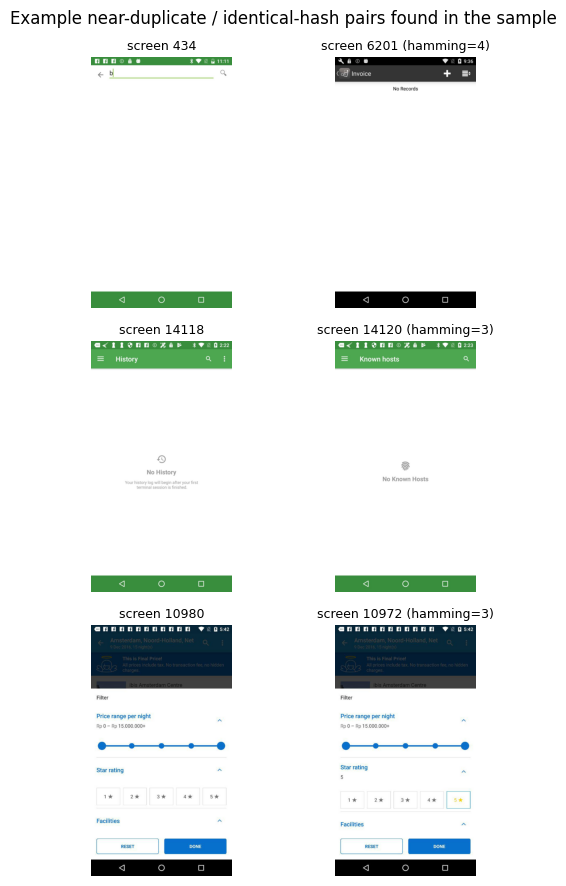

In [ ]:
# showing up to 3 example pairs
example_pairs = (list(identical_pairs) + list(near_dup_pairs))[:3]

if example_pairs:
    fig, axes = plt.subplots(len(example_pairs), 2, figsize=(6, 3 * len(example_pairs)))
    axes = np.atleast_2d(axes)
    for row_ax, (a, b) in zip(axes, example_pairs):
        idx_a, idx_b = sample_idx[a], sample_idx[b]
        row_ax[0].imshow(split[idx_a][IMAGE_COL]); row_ax[0].axis("off")
        row_ax[0].set_title(f"screen {idx_a}", fontsize=9)
        row_ax[1].imshow(split[idx_b][IMAGE_COL]); row_ax[1].axis("off")
        row_ax[1].set_title(f"screen {idx_b} (hamming={hamming[a, b]})", fontsize=9)
    fig.suptitle("Example near-duplicate / identical-hash pairs found in the sample")
    fig.tight_layout()
    fig.savefig("results/figures/fig4_near_duplicate_pairs.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print(f"No identical-hash or near-duplicate (<= {NEAR_DUP_THRESHOLD}-bit) pairs found in this "
          f"{len(sample_idx)}-screen sample, nothing to show.")


## App-level grouping check (for leakage-safe splitting)

Multiple screens from the same app tend to look visually very similar. So if one screen from an app lands in `train` and another lands in `test`, the
model can get a high score by recognising the *app*, not by understanding the *caption*. This is a leakage/shortcut problem. The fix used is to split by **app**,
not by screen, so every screen from a given app stays in exactly one split. It is executed in notebbok 2 for preprocessing.


In [ ]:
if APP_COL is not None:
    app_counts = pd.Series([split[i][APP_COL] for i in range(len(split))]).value_counts()
    print(f"Unique apps: {len(app_counts)}")
    print(app_counts.describe())
else:
    print("No explicit app-package column was found in this schema.")


Unique apps: 4390
count    4390.000000
mean        3.586105
std         3.635943
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max        45.000000
Name: count, dtype: float64


## Visualisations

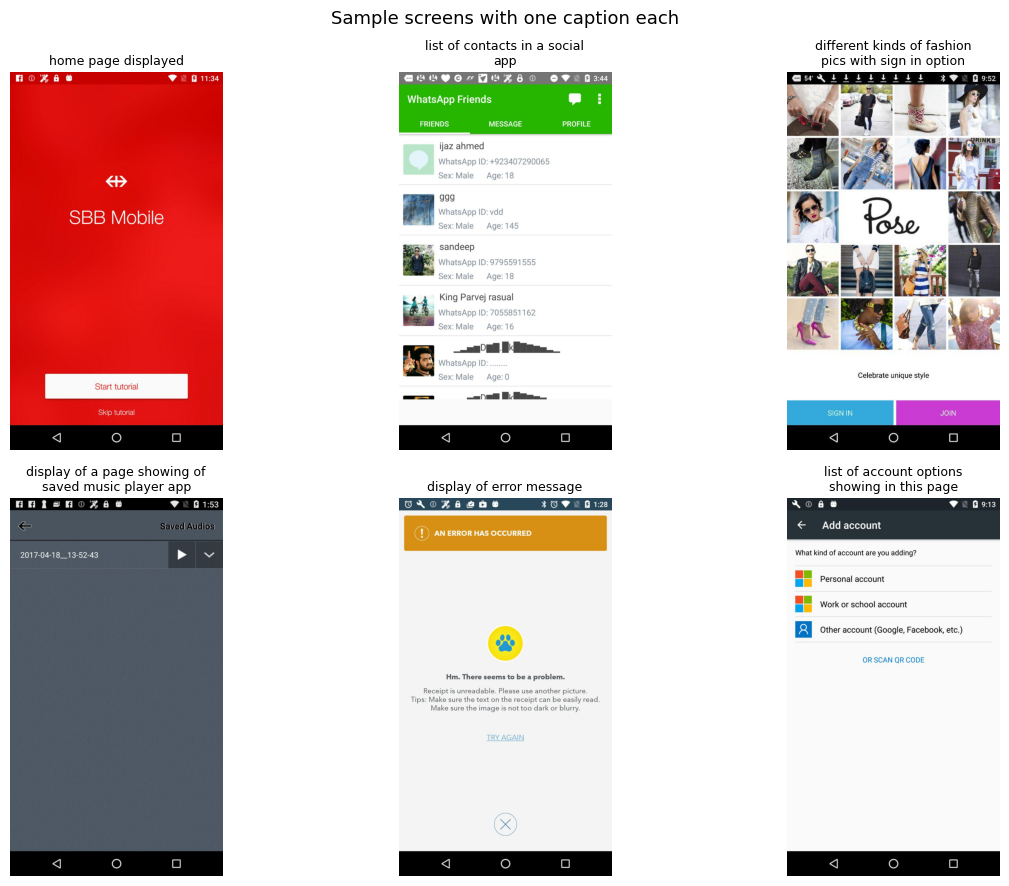

In [ ]:
import textwrap

fig, axes = plt.subplots(2, 3, figsize=(13, 9))
sample_for_grid = rng.sample(range(len(split)), 6)

for ax, i in zip(axes.flat, sample_for_grid):
    row = split[i]
    img = row[IMAGE_COL]
    cap_val = row[CAPTION_COL]
    cap = cap_val[0] if isinstance(cap_val, (list, tuple)) else cap_val
    ax.imshow(img)
    ax.set_title(textwrap.fill(cap, 28), fontsize=9)
    ax.axis("off")

fig.suptitle("Sample screens with one caption each", fontsize=13)
fig.tight_layout()
fig.savefig("results/figures/fig1_sample_screens.png", dpi=150, bbox_inches="tight")
plt.show()


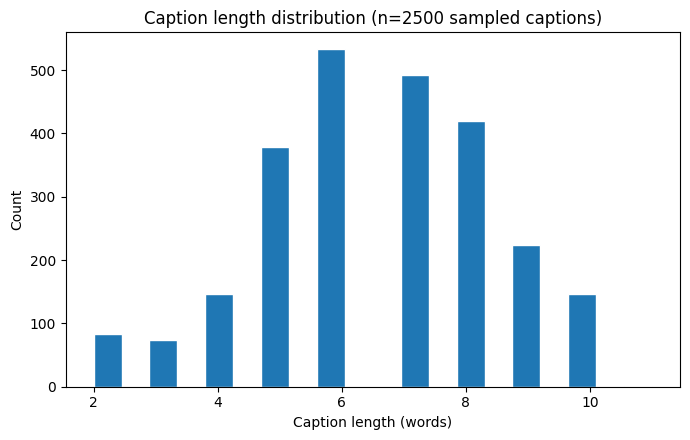

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(caption_lengths, bins=20, edgecolor="white")
ax.set_xlabel("Caption length (words)")
ax.set_ylabel("Count")
ax.set_title(f"Caption length distribution (n={len(caption_lengths)} sampled captions)")
fig.tight_layout()
fig.savefig("results/figures/fig2_caption_length_hist.png", dpi=150, bbox_inches="tight")
plt.show()


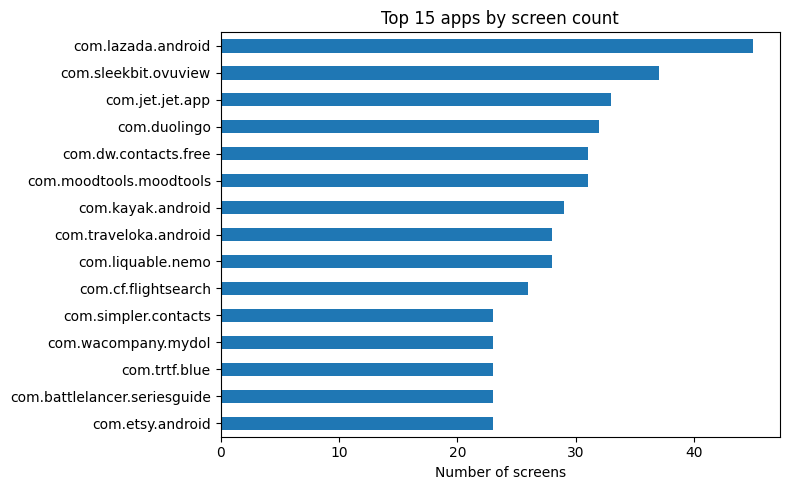

In [ ]:
if APP_COL is not None:
    top_apps = app_counts.head(15)
    fig, ax = plt.subplots(figsize=(8, 5))
    top_apps.plot(kind="barh", ax=ax)
    ax.invert_yaxis()
    ax.set_xlabel("Number of screens")
    ax.set_title("Top 15 apps by screen count")
    fig.tight_layout()
    fig.savefig("results/figures/fig3_screens_per_app.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("Skipped, no app column available in this schema.")


## Save a dataset summary table



In [ ]:
summary_row = {
    "total_screens": split_summary["rows"].sum(),              # was: len(split)  -> now 22417, matches captions below
    "total_captions_dataset": split_summary["total_captions"].sum(),  # renamed from total_captions_sampled_estimate
    "mean_caption_length_words": round(float(np.mean(caption_lengths)), 2),
    "pct_exact_duplicate_captions_sampled": round(100 * (n_total - n_unique) / n_total, 2),
    "corrupt_images_in_sample": n_bad_images,
    "identical_dhash_image_pairs_sampled": int(len(identical_pairs)),
    "near_duplicate_dhash_image_pairs_sampled": int(len(near_dup_pairs)),
    "pct_screens_in_dhash_dup_or_near_dup_sampled": round(100 * n_screens_involved / len(sample_idx), 2),
    "unique_apps": len(app_counts) if APP_COL is not None else "unknown",
}
summary_df = pd.DataFrame([summary_row])
summary_df.to_csv("results/tables/data_summary.csv", index=False)
summary_df


,total_screens,total_captions_dataset,mean_caption_length_words,pct_exact_duplicate_captions_sampled,corrupt_images_in_sample,identical_dhash_image_pairs_sampled,near_duplicate_dhash_image_pairs_sampled,pct_screens_in_dhash_dup_or_near_dup_sampled,unique_apps
0,22417,112085,6.55,6.4,0,0,3,1.2,4390
